<a href="https://colab.research.google.com/github/uhyeon1222-bit/work/blob/main/%EC%93%B0%EB%A0%88%EA%B8%B0_%EC%9D%B4%EB%AF%B8%EC%A7%80_%EB%B6%84%EB%A5%98_5756254_%EA%B9%80%EC%9A%B0%ED%98%84.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Cell 1: 환경 설정 및 캐글 데이터셋 다운로드

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix

import kagglehub

# 1. 재현성을 위한 시드(Seed) 고정
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(42)

# GPU 확인
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"사용 중인 디바이스: {device}")

# 2. 캐글 데이터셋 다운로드
path = kagglehub.dataset_download("mostafaabla/garbage-classification")
data_dir = os.path.join(path, "garbage_classification")
print("데이터셋 경로:", data_dir)

사용 중인 디바이스: cuda
Using Colab cache for faster access to the 'garbage-classification' dataset.
데이터셋 경로: /kaggle/input/garbage-classification/garbage_classification


## Cell 2: 데이터 탐색 (EDA) 및 분포 그래프 생성

총 클래스 개수 (12개): ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
총 이미지 개수: 15515장


/tmp/ipykernel_406/1485303278.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=counts_df, x='Class', y='Count', palette='viridis')


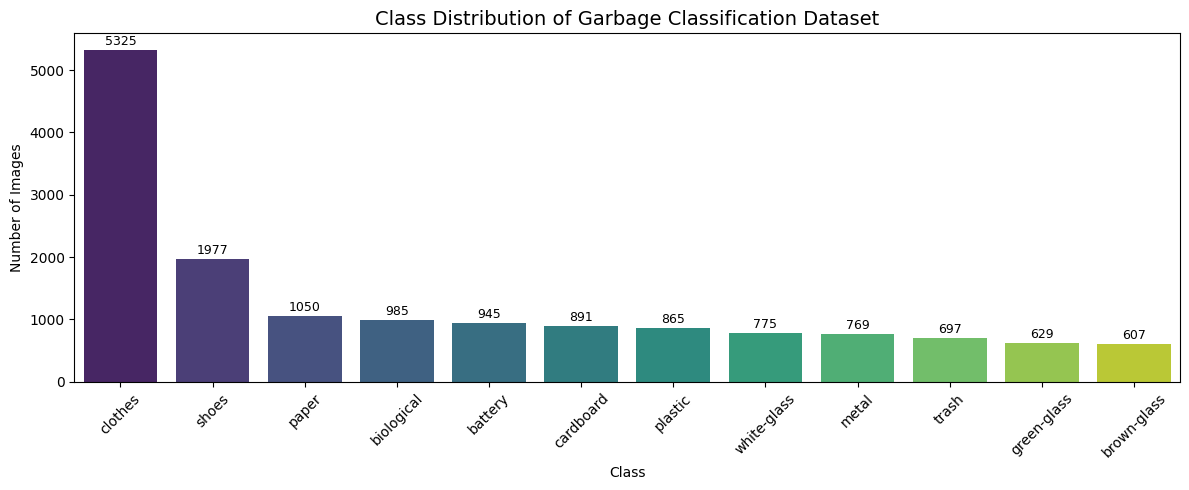

In [ ]:
# 전체 데이터셋 로드
raw_dataset = datasets.ImageFolder(root=data_dir)
class_names = raw_dataset.classes
num_classes = len(class_names)
print(f"총 클래스 개수 ({num_classes}개): {class_names}")
print(f"총 이미지 개수: {len(raw_dataset)}장")

# 클래스별 이미지 개수 카운트
targets = raw_dataset.targets
class_counts = Counter(targets)
counts_df = pd.DataFrame({
    'Class': [class_names[i] for i in range(num_classes)],
    'Count': [class_counts[i] for i in range(num_classes)]
}).sort_values(by='Count', ascending=False)

# 막대그래프 시각화
plt.figure(figsize=(12, 5))
sns.barplot(data=counts_df, x='Class', y='Count', palette='viridis')
plt.title('Class Distribution of Garbage Classification Dataset', fontsize=14)
plt.xticks(rotation=45)
plt.ylabel('Number of Images')
for idx, row in enumerate(counts_df.itertuples()):
    plt.text(idx, row.Count + 80, str(row.Count), ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('eda_class_distribution.png', dpi=300)
plt.show()

## Cell 3: 데이터 분할 및 AI 이미지 대응용 데이터 증강 (Data Augmentation)

In [ ]:
# 하이퍼파라미터 딕셔너리
CONFIG = {
    "model_name": "convnext_tiny",
    "img_size": 224,
    "batch_size": 32,
    "epochs": 15,
    "lr": 1e-4,
    "weight_decay": 1e-2,
    "dropout": 0.3,
    "use_augmentation": True,
    "use_class_weights": True
}

# ImageNet 표준 정규화 값
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# 학습용 전처리
if CONFIG["use_augmentation"]:
    train_transform = transforms.Compose([
        transforms.RandomResizedCrop(CONFIG["img_size"], scale=(0.7, 1.0)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=20),
        # AI 생성 이미지의 과장된 색감/조명 변화 대응
        transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD)
    ])
else:
    # 과적합 비교 실험(Baseline)을 위한 무증강 전처리
    train_transform = transforms.Compose([
        transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD)
    ])

# 검증 및 테스트용 전처리
val_transform = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# Stratified Split (클래스 비율을 유지하며 8:2로 학습/검증 분할)
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(sss.split(np.zeros(len(targets)), targets))

train_full = datasets.ImageFolder(root=data_dir, transform=train_transform)
val_full = datasets.ImageFolder(root=data_dir, transform=val_transform)

train_dataset = Subset(train_full, train_idx)
val_dataset = Subset(val_full, val_idx)

train_loader = DataLoader(train_dataset, batch_size=CONFIG["batch_size"], shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG["batch_size"], shuffle=False, num_workers=2, pin_memory=True)

print(f"학습 데이터: {len(train_dataset)}장 | 검증 데이터: {len(val_dataset)}장")

학습 데이터: 12412장 | 검증 데이터: 3103장


## Cell 4: 모델 정의

In [ ]:
def build_model(model_name, num_classes, dropout_rate=0.3):
    if model_name == "resnet18":
        model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(in_features, num_classes)
        )
    elif model_name == "efficientnet_b0":
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        in_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(in_features, num_classes)
        )
    elif model_name == "convnext_tiny":
        model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.DEFAULT)
        in_features = model.classifier[2].in_features
        model.classifier[2] = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(in_features, num_classes)
        )
    else:
        raise ValueError("지원하지 않는 모델명입니다.")
    return model.to(device)

model = build_model(CONFIG["model_name"], num_classes, CONFIG["dropout"])

# 클래스 불균형 해소를 위한 가중치 계산
if CONFIG["use_class_weights"]:
    train_targets = [targets[i] for i in train_idx]
    class_sample_counts = np.array([train_targets.count(i) for i in range(num_classes)])
    weights = 1. / np.sqrt(class_sample_counts) # 완화된 역빈도 가중치
    weights = weights / weights.sum() * num_classes
    class_weights = torch.FloatTensor(weights).to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1) # Label Smoothing으로 과적합 방지
else:
    criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(model.parameters(), lr=CONFIG["lr"], weight_decay=CONFIG["weight_decay"])
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG["epochs"], eta_min=1e-6)

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 116MB/s]


## Cell 5: 학습 루프 및 최고 성능 모델 저장

In [ ]:
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_acc = 0.0

for epoch in range(CONFIG["epochs"]):
    # --- Train Phase ---
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    train_loss = running_loss / total
    train_acc = 100. * correct / total

    # --- Validation Phase ---
    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()

    val_loss = val_running_loss / val_total
    val_acc = 100. * val_correct / val_total

    scheduler.step()

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    # 최고 성능 모델 저장
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), f"best_{CONFIG['model_name']}.pth")
        save_msg = "--> [Best Model Saved]"
    else:
        save_msg = ""

    print(f"Epoch [{epoch+1:02d}/{CONFIG['epochs']:02d}] "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}% {save_msg}")

print(f"\n학습 완료! 최고 검증 정확도: {best_val_acc:.2f}%")

Epoch [01/15] Train Loss: 0.9834 | Train Acc: 90.21% | Val Loss: 0.7450 | Val Acc: 96.39% --> [Best Model Saved]
Epoch [02/15] Train Loss: 0.7438 | Train Acc: 96.91% | Val Loss: 0.7106 | Val Acc: 97.33% --> [Best Model Saved]
Epoch [03/15] Train Loss: 0.7049 | Train Acc: 98.05% | Val Loss: 0.7245 | Val Acc: 97.16% 
Epoch [04/15] Train Loss: 0.6886 | Train Acc: 98.41% | Val Loss: 0.6943 | Val Acc: 98.13% --> [Best Model Saved]
Epoch [05/15] Train Loss: 0.6755 | Train Acc: 98.97% | Val Loss: 0.6864 | Val Acc: 98.03% 
Epoch [06/15] Train Loss: 0.6634 | Train Acc: 99.29% | Val Loss: 0.7033 | Val Acc: 97.68% 
Epoch [07/15] Train Loss: 0.6600 | Train Acc: 99.34% | Val Loss: 0.6893 | Val Acc: 98.13% 
Epoch [08/15] Train Loss: 0.6544 | Train Acc: 99.43% | Val Loss: 0.6833 | Val Acc: 98.32% --> [Best Model Saved]
Epoch [09/15] Train Loss: 0.6562 | Train Acc: 99.36% | Val Loss: 0.6826 | Val Acc: 98.42% --> [Best Model Saved]
Epoch [10/15] Train Loss: 0.6483 | Train Acc: 99.68% | Val Loss: 0.6901

## Cell 6: 학습 곡선 및 혼동 행렬 시각화

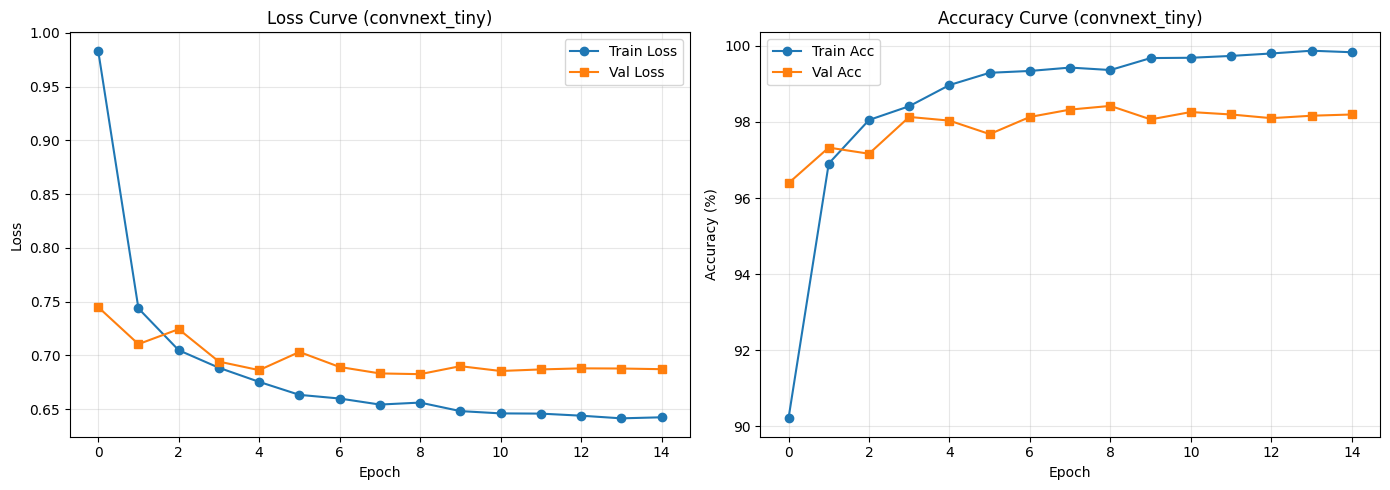


[분류 성능 리포트]
              precision    recall  f1-score   support

     battery     0.9844    1.0000    0.9921       189
  biological     0.9949    0.9848    0.9898       197
 brown-glass     0.9839    1.0000    0.9919       122
   cardboard     0.9943    0.9719    0.9830       178
     clothes     0.9962    0.9878    0.9920      1065
 green-glass     1.0000    0.9841    0.9920       126
       metal     0.9557    0.9805    0.9679       154
       paper     0.9905    0.9905    0.9905       210
     plastic     0.9330    0.9653    0.9489       173
       shoes     0.9653    0.9873    0.9762       395
       trash     0.9929    1.0000    0.9964       139
 white-glass     0.9864    0.9355    0.9603       155

    accuracy                         0.9842      3103
   macro avg     0.9814    0.9823    0.9817      3103
weighted avg     0.9845    0.9842    0.9842      3103



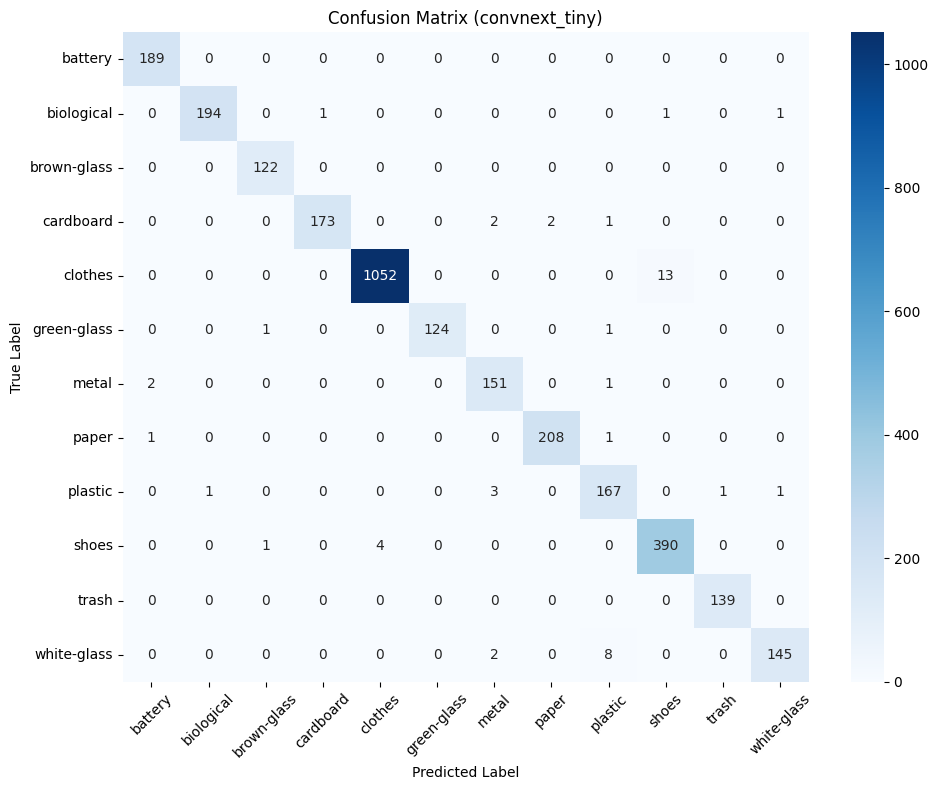

In [ ]:
# 1. Loss & Accuracy 곡선
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history['train_loss'], label='Train Loss', marker='o')
axes[0].plot(history['val_loss'], label='Val Loss', marker='s')
axes[0].set_title(f"Loss Curve ({CONFIG['model_name']})")
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history['train_acc'], label='Train Acc', marker='o')
axes[1].plot(history['val_acc'], label='Val Acc', marker='s')
axes[1].set_title(f"Accuracy Curve ({CONFIG['model_name']})")
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"curve_{CONFIG['model_name']}.png", dpi=300)
plt.show()

# 2. Best 모델 로드 후 Confusion Matrix 출력
model.load_state_dict(torch.load(f"best_{CONFIG['model_name']}.pth"))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print("\n[분류 성능 리포트]")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title(f"Confusion Matrix ({CONFIG['model_name']})")
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"cm_{CONFIG['model_name']}.png", dpi=300)
plt.show()